# Co-registration quality control

Overview of the co-registration of the REMA strips, based on the QC table written by `ptools.coregistration` (`coreg_quality_control.csv`).

Note that all RMSE values in the table are computed on the same POCA/SWATH points that the plane was fitted to. They say how well the plane fits the reference data, not how good the strip is away from those points. That is why this notebook also looks at how large the applied correction is across each strip's footprint.

In [1]:
project_crs = "EPSG:3031"

projectDir = "/Users/b513882/Library/CloudStorage/Dropbox/REMA-strips-correction"

region_id = "PIG"

# Thresholds used when running ptools.coregistration
# Keep these in sync with the call in data-preprocessing.ipynb
thresholds = dict(
    min_poca=10,
    min_swath=20,
    min_footprint_coverage=0.20,
    min_covered_quadrants=3,
    max_rmse_m=10.0,
    max_rejected_fraction=0.5,
)

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

# Status colours (with a distinct marker each, so status is never colour alone)
STATUS_STYLE = {
    "OK":          dict(color="#0ca30c", marker="o"),
    "FLAGGED":     dict(color="#eda100", marker="s"),
    "UNCORRECTED": dict(color="#d03b3b", marker="X"),
    "FAILED":      dict(color="#52514e", marker="^"),
}
STATUS_ORDER = [s for s in STATUS_STYLE]

def status_legend(ax, statuses, **kwargs):
    handles = [Line2D([], [], linestyle="", markersize=7, label=s, **STATUS_STYLE[s])
               for s in STATUS_ORDER if s in set(statuses)]
    ax.legend(handles=handles, frameon=False, **kwargs)

## Load the QC table

Each strip's REMA index footprint is added so the correction can be evaluated over the area the strip actually covers.

In [3]:
qc_dir = Path(projectDir) / "data/interim" / f"region-{region_id}" / "REMA/co-registered-strips"
qc = pd.read_csv(qc_dir / "coreg_quality_control.csv")

qc["quality_flags"] = qc["quality_flags"].fillna("")
qc["flags"] = qc["quality_flags"].apply(lambda s: [f for f in s.split(";") if f])
qc["dem_id"] = qc["strip"].str.replace(r"_dem(?:_[0-9.]+m)?\.tif$", "", regex=True)
qc["acquisition_time"] = pd.to_datetime(qc["acquisition_time_utc"], utc=True)

# Derived quantities
# The correction subtracted from the DEM is a*(x-x0) + b*(y-y0) + c, with a and b in m/m
qc["tilt_m_per_km"] = 1000 * np.hypot(qc["a"], qc["b"])
qc["rmse_change"] = qc["rmse_after"] - qc["rmse_before"]
qc["rejected_fraction"] = qc["n_rejected"] / qc["n_total"]

print(f"{len(qc)} strips")
qc["status"].value_counts().reindex(STATUS_ORDER).dropna().astype(int).to_frame()

119 strips


,count
status,
OK,26
FLAGGED,80
UNCORRECTED,13


In [4]:
# Strip footprints from the REMA strip index
aoi = gpd.read_file(f"{projectDir}/data/initial/regions/region-{region_id}.shp").to_crs(project_crs)
index = gpd.read_file(
    f"{projectDir}/data/initial/REMA/REMA_Strip_Index_s2s041.shp",
    bbox=tuple(aoi.to_crs("EPSG:4326").total_bounds),
)
footprints = index[["dem_id", "geometry"]].to_crs(project_crs)
qc = gpd.GeoDataFrame(qc.merge(footprints, on="dem_id", how="left"), geometry="geometry", crs=project_crs)
print(f"Footprints found for {qc.geometry.notna().sum()} of {len(qc)} strips")

Footprints found for 119 of 119 strips


In [5]:
def footprint_vertices(geom):
    polys = getattr(geom, "geoms", [geom])
    return np.vstack([np.asarray(p.exterior.coords) for p in polys])

def correction_extremes(row):
    # The plane is linear, so its extremes over the footprint lie on the footprint's vertices
    if row.geometry is None or not np.isfinite(row["c"]):
        return pd.Series({"correction_min": np.nan, "correction_max": np.nan})
    xy = footprint_vertices(row.geometry)
    plane = row["a"] * (xy[:, 0] - row["x0"]) + row["b"] * (xy[:, 1] - row["y0"]) + row["c"]
    return pd.Series({"correction_min": plane.min(), "correction_max": plane.max()})

qc[["correction_min", "correction_max"]] = qc.apply(correction_extremes, axis=1)
qc["max_abs_correction"] = qc[["correction_min", "correction_max"]].abs().max(axis=1)
# How much the correction varies across the strip (the tilt part only)
qc["correction_range"] = qc["correction_max"] - qc["correction_min"]

## 1. Status and flags

How often each flag is raised, and which flags occur together.

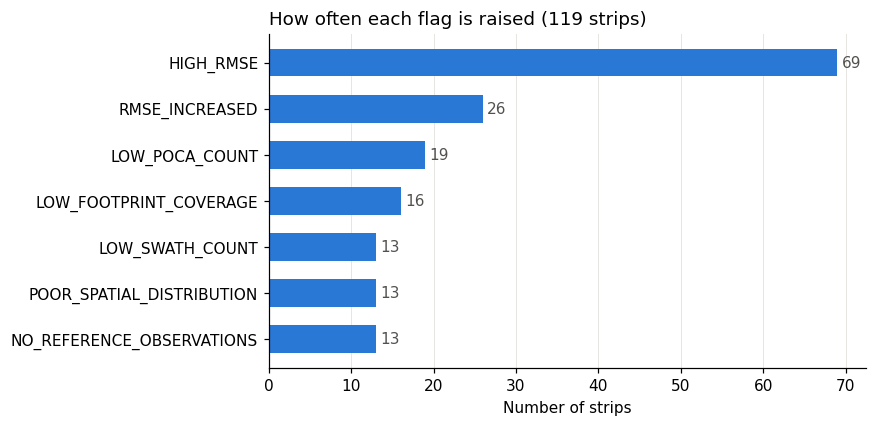

In [6]:
flag_counts = qc.explode("flags")["flags"].dropna().value_counts()

fig, ax = plt.subplots(figsize=(7, 0.45 * len(flag_counts) + 0.8))
ax.barh(flag_counts.index[::-1], flag_counts.values[::-1], color="#2a78d6", height=0.6)
for y, v in enumerate(flag_counts.values[::-1]):
    ax.text(v + 0.5, y, str(v), va="center", color="#52514e")
ax.set_xlabel("Number of strips")
ax.set_title(f"How often each flag is raised ({len(qc)} strips)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

In [7]:
# Flag combinations
combos = (qc.assign(combination=qc["quality_flags"].replace("", "(none)"))
            .groupby(["status", "combination"]).size()
            .rename("n_strips").reset_index()
            .sort_values("n_strips", ascending=False))
combos

,status,combination,n_strips
0,FLAGGED,HIGH_RMSE,46
8,OK,(none),26
1,FLAGGED,HIGH_RMSE;RMSE_INCREASED,18
9,UNCORRECTED,LOW_POCA_COUNT;LOW_SWATH_COUNT;LOW_FOOTPRINT_C...,13
7,FLAGGED,RMSE_INCREASED,8
5,FLAGGED,LOW_POCA_COUNT;HIGH_RMSE,3
4,FLAGGED,LOW_POCA_COUNT,2
2,FLAGGED,LOW_FOOTPRINT_COVERAGE,1
3,FLAGGED,LOW_FOOTPRINT_COVERAGE;HIGH_RMSE,1
6,FLAGGED,LOW_POCA_COUNT;LOW_FOOTPRINT_COVERAGE;HIGH_RMSE,1


## 2. Fit to the reference data

Points below the 1:1 line improved with the co-registration. The dashed line is `max_rmse_m`: strips above it get `HIGH_RMSE`.

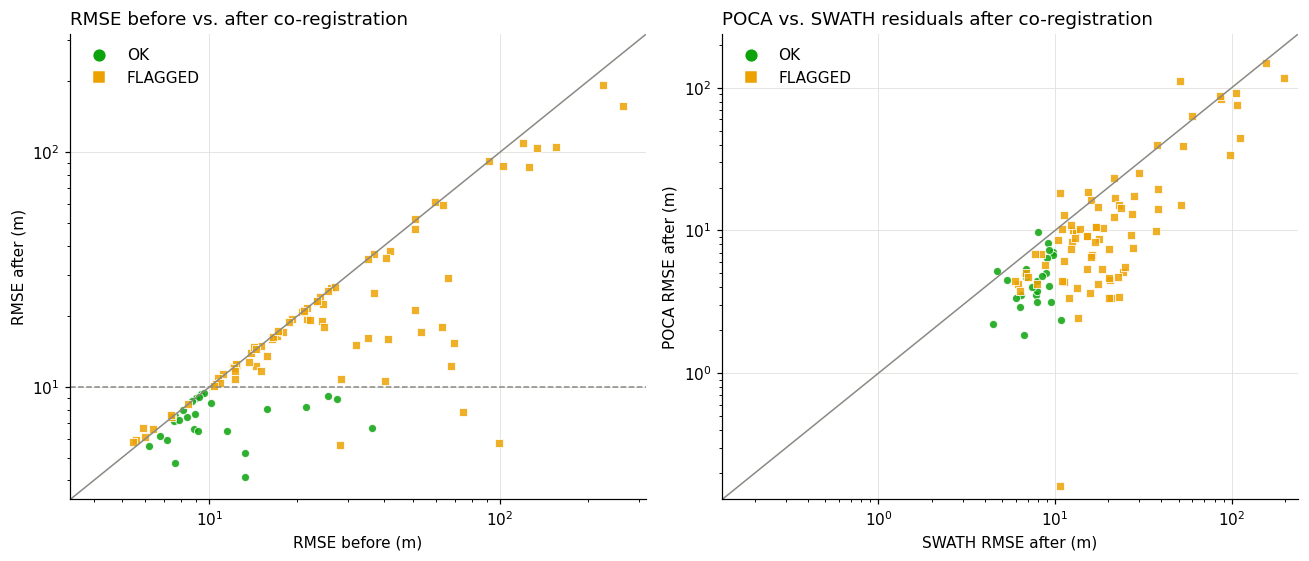

In [8]:
fitted = qc[qc["rmse_after"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

ax = axes[0]
for s in STATUS_ORDER:
    d = fitted[fitted["status"] == s]
    if len(d):
        ax.scatter(d["rmse_before"], d["rmse_after"], s=28, alpha=0.85,
                   edgecolor="white", linewidth=0.6, **STATUS_STYLE[s])
lims = [fitted[["rmse_before", "rmse_after"]].min().min() * 0.8,
        fitted[["rmse_before", "rmse_after"]].max().max() * 1.2]
ax.plot(lims, lims, color="#8a8984", linewidth=1)
ax.axhline(thresholds["max_rmse_m"], color="#8a8984", linestyle="--", linewidth=1)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="RMSE before (m)", ylabel="RMSE after (m)")
ax.set_title("RMSE before vs. after co-registration", loc="left")
status_legend(ax, fitted["status"].unique(), loc="upper left")

ax = axes[1]
for s in STATUS_ORDER:
    d = fitted[fitted["status"] == s]
    if len(d):
        ax.scatter(d["rmse_swath_after"], d["rmse_poca_after"], s=28, alpha=0.85,
                   edgecolor="white", linewidth=0.6, **STATUS_STYLE[s])
lims = [fitted[["rmse_swath_after", "rmse_poca_after"]].min().min() * 0.8,
        fitted[["rmse_swath_after", "rmse_poca_after"]].max().max() * 1.2]
ax.plot(lims, lims, color="#8a8984", linewidth=1)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="SWATH RMSE after (m)", ylabel="POCA RMSE after (m)")
ax.set_title("POCA vs. SWATH residuals after co-registration", loc="left")
status_legend(ax, fitted["status"].unique(), loc="upper left")

plt.tight_layout()
plt.show()

In [9]:
fitted[["rmse_before", "rmse_after", "rmse_poca_after", "rmse_swath_after", "rejected_fraction"]].describe().round(2)

,rmse_before,rmse_after,rmse_poca_after,rmse_swath_after,rejected_fraction
count,106.00,106.00,104.00,106.00,106.00
mean,32.77,23.18,15.87,23.82,0.18
std,41.89,30.48,25.92,30.98,0.24
min,5.44,4.14,0.16,4.47,0.00
25%,10.40,8.11,4.42,8.53,0.04
50%,17.53,12.67,6.99,13.38,0.09
75%,35.94,21.27,12.93,22.63,0.20
max,264.90,192.55,149.04,197.82,0.96


## 3. Size of the correction

- **Offset** `c`: the vertical shift at the strip centre.
- **Tilt**: the slope of the plane in m/km.
- **Largest correction**: the largest absolute correction anywhere on the strip footprint. A modest tilt can still give a large correction at the far end of a long strip, especially if the reference points are clustered at one end.

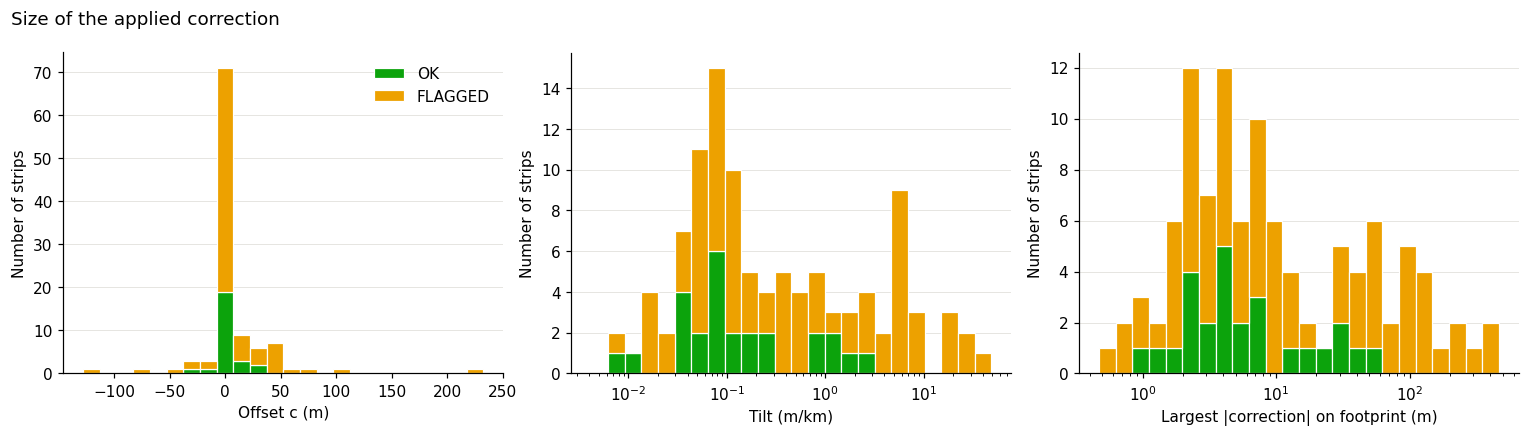

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [
    ("c", "Offset c (m)", False),
    ("tilt_m_per_km", "Tilt (m/km)", True),
    ("max_abs_correction", "Largest |correction| on footprint (m)", True),
]
for ax, (col, label, log) in zip(axes, panels):
    groups = [fitted.loc[fitted["status"] == s, col].dropna() for s in ["OK", "FLAGGED"]]
    values = pd.concat(groups)
    if log:
        bins = np.logspace(np.log10(max(values[values > 0].min(), 1e-3)), np.log10(values.max()), 25)
        ax.set_xscale("log")
    else:
        bins = np.linspace(values.min(), values.max(), 25)
    ax.hist(groups, bins=bins, stacked=True, label=["OK", "FLAGGED"],
            color=[STATUS_STYLE[s]["color"] for s in ["OK", "FLAGGED"]],
            edgecolor="white", linewidth=0.8)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of strips")
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.suptitle("Size of the applied correction", x=0.01, ha="left")
plt.tight_layout()
plt.show()

In [11]:
fitted = qc[qc["rmse_after"].notna()]
fitted[["c", "tilt_m_per_km", "correction_range", "max_abs_correction"]].describe().round(2)

,c,tilt_m_per_km,correction_range,max_abs_correction
count,106.00,106.00,106.00,106.00
mean,6.68,2.60,45.99,38.43
std,33.34,6.87,111.60,80.19
min,-127.88,0.00,0.12,0.47
25%,-1.32,0.06,2.64,2.98
50%,1.12,0.15,5.53,6.77
75%,6.92,1.49,32.05,37.80
max,232.61,48.76,813.38,467.77


## 4. Correction over time

A systematic trend in the offset with acquisition date could point to a bias in the reference data or in the strips, rather than random errors.

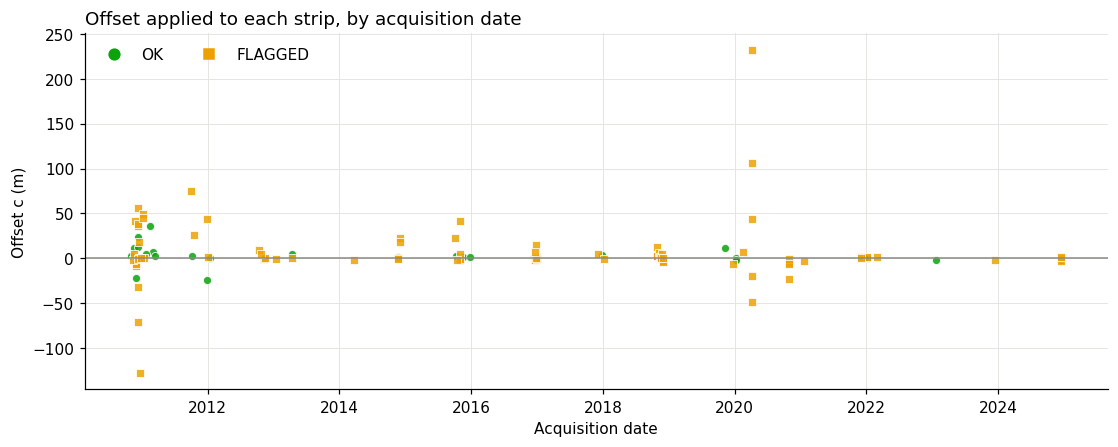

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.2))
for s in STATUS_ORDER:
    d = fitted[fitted["status"] == s]
    if len(d):
        ax.scatter(d["acquisition_time"], d["c"], s=28, alpha=0.85,
                   edgecolor="white", linewidth=0.6, **STATUS_STYLE[s])
ax.axhline(0, color="#8a8984", linewidth=1)
ax.set(xlabel="Acquisition date", ylabel="Offset c (m)")
ax.set_title("Offset applied to each strip, by acquisition date", loc="left")
status_legend(ax, fitted["status"].unique(), loc="upper left", ncol=3)
plt.show()

## 5. Map

Strip footprints, one panel per status, with all other footprints in grey behind them.

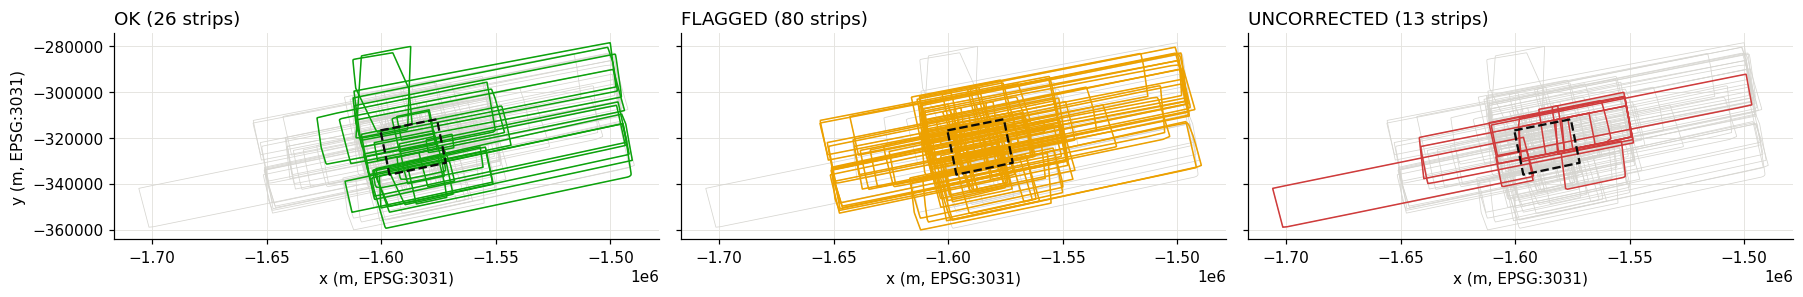

In [13]:
statuses = [s for s in STATUS_ORDER if (qc["status"] == s).any()]
fig, axes = plt.subplots(1, len(statuses), figsize=(5.5 * len(statuses), 4.5), sharex=True, sharey=True)
for ax, s in zip(np.atleast_1d(axes), statuses):
    qc.boundary.plot(ax=ax, color="#d6d5d0", linewidth=0.5)
    qc[qc["status"] == s].boundary.plot(ax=ax, color=STATUS_STYLE[s]["color"], linewidth=1)
    aoi.boundary.plot(ax=ax, color="#0b0b0b", linewidth=1.5, linestyle="--")
    ax.set_title(f"{s} ({(qc['status'] == s).sum()} strips)", loc="left")
    ax.set_aspect("equal")
    ax.set_xlabel("x (m, EPSG:3031)")
np.atleast_1d(axes)[0].set_ylabel("y (m, EPSG:3031)")
plt.tight_layout()
plt.show()

Largest correction per strip, shown at each footprint's centroid (log colour scale).

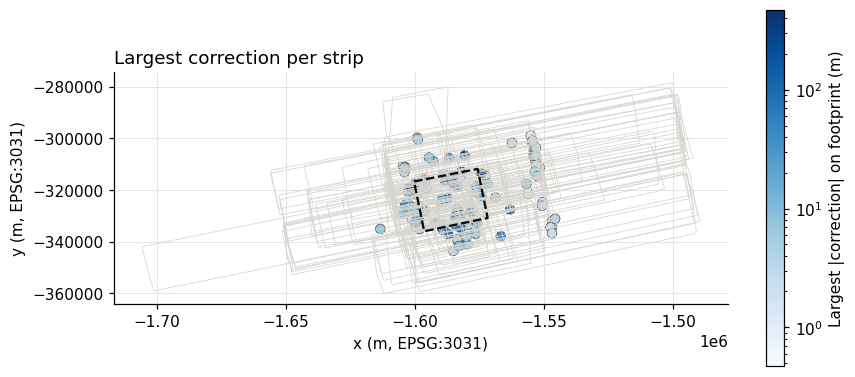

In [14]:
from matplotlib.colors import LogNorm

d = qc[qc["max_abs_correction"].notna()].sort_values("max_abs_correction")
centroids = d.geometry.centroid

fig, ax = plt.subplots(figsize=(9, 6))
qc.boundary.plot(ax=ax, color="#d6d5d0", linewidth=0.5)
aoi.boundary.plot(ax=ax, color="#0b0b0b", linewidth=1.5, linestyle="--")
sc = ax.scatter(centroids.x, centroids.y, c=d["max_abs_correction"], cmap="Blues",
                norm=LogNorm(vmin=max(d["max_abs_correction"].min(), 0.1), vmax=d["max_abs_correction"].max()),
                s=40, edgecolor="#52514e", linewidth=0.5)
fig.colorbar(sc, ax=ax, shrink=0.7, label="Largest |correction| on footprint (m)")
ax.set_aspect("equal")
ax.set(xlabel="x (m, EPSG:3031)", ylabel="y (m, EPSG:3031)")
ax.set_title("Largest correction per strip", loc="left")
plt.show()

## 6. Sensitivity to the thresholds

All flags are computed from columns in the QC table, so they can be re-applied with different thresholds without re-running the co-registration. This uses the same logic as `_coreg_process_one`.

In [15]:
def apply_flags(qc, min_poca, min_swath, min_footprint_coverage, min_covered_quadrants, max_rmse_m,
                max_rejected_fraction):
    flags = pd.DataFrame({
        "LOW_POCA_COUNT": qc["n_poca"] < min_poca,
        "LOW_SWATH_COUNT": qc["n_swath"] < min_swath,
        "LOW_FOOTPRINT_COVERAGE": qc["combined_coverage_fraction"] < min_footprint_coverage,
        "POOR_SPATIAL_DISTRIBUTION": qc["n_covered_quadrants"] < min_covered_quadrants,
        "OFFSET_ONLY": qc["fit_mode"] == "offset_only",
        "HIGH_RMSE": qc["rmse_after"] > max_rmse_m,
        "RMSE_INCREASED": qc["weighted_rmse_after"] > qc["weighted_rmse_before"],
        "HIGH_REJECTION": qc["rejected_fraction"] > max_rejected_fraction,
    }, index=qc.index)
    status = np.where(flags.any(axis=1), "FLAGGED", "OK")
    status = np.where(qc["n_total"] == 0, "UNCORRECTED", status)
    status = np.where(qc["status"] == "FAILED", "FAILED", status)
    return pd.Series(status, index=qc.index), flags

# Check that the current thresholds reproduce the stored status
status, flags = apply_flags(qc, **thresholds)
mismatch = (status != qc["status"]).sum()
if mismatch == 0:
    print("Recomputed status matches the QC table")
else:
    # Expected if the QC table was written before HIGH_REJECTION and the weighted RMSE_INCREASED check were added
    print(f"{mismatch} strips differ from the QC table. Re-run ptools.coregistration to update it.")
    display(pd.crosstab(qc["status"].rename("in QC table"), status.rename("recomputed")))

8 strips differ from the QC table. Re-run ptools.coregistration to update it.


recomputed,FLAGGED,OK,UNCORRECTED
in QC table,,,
FLAGGED,72,8,0
OK,0,26,0
UNCORRECTED,0,0,13


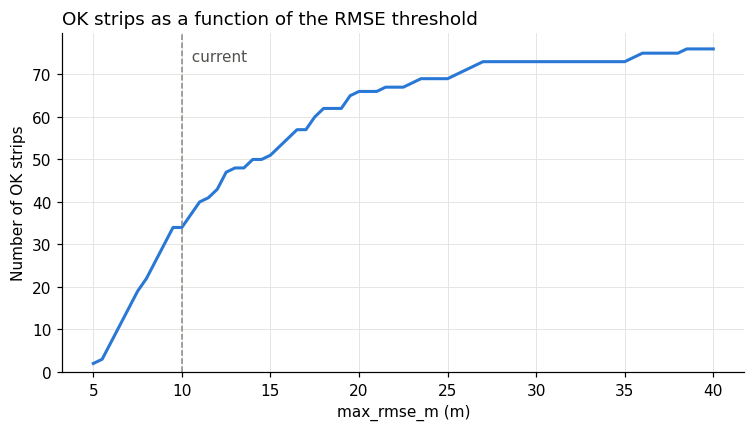

In [16]:
rmse_values = np.arange(5, 40.5, 0.5)
n_ok = [(apply_flags(qc, **{**thresholds, "max_rmse_m": v})[0] == "OK").sum() for v in rmse_values]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rmse_values, n_ok, color="#2a78d6", linewidth=2)
ax.axvline(thresholds["max_rmse_m"], color="#8a8984", linestyle="--", linewidth=1)
ax.text(thresholds["max_rmse_m"], max(n_ok), "  current", va="top", color="#52514e")
ax.set(xlabel="max_rmse_m (m)", ylabel="Number of OK strips", ylim=(0, None))
ax.set_title("OK strips as a function of the RMSE threshold", loc="left")
plt.show()

In [17]:
# Which strips fail on a single flag only? These are the ones closest to passing
single = flags[flags.sum(axis=1) == 1].idxmax(axis=1).value_counts().rename("strips flagged by this flag alone")
single.to_frame()

,strips flagged by this flag alone
HIGH_RMSE,45
LOW_POCA_COUNT,2
LOW_FOOTPRINT_COVERAGE,1


## 7. Strips to inspect more closely

A shortlist for the per-strip diagnostics (layer 2):

- strips where the RMSE increased
- the largest corrections
- OK strips with a large tilt or correction, which pass all checks but may still be wrong away from the reference points

In [18]:
cols = ["strip", "status", "quality_flags", "n_total", "combined_coverage_fraction",
        "rmse_before", "rmse_after", "c", "tilt_m_per_km", "max_abs_correction"]

shortlist = pd.concat([
    qc[qc["rmse_change"] > 0].assign(reason="RMSE increased"),
    qc.nlargest(10, "max_abs_correction").assign(reason="Largest correction"),
    qc[qc["status"] == "OK"].nlargest(5, "max_abs_correction").assign(reason="OK, largest correction"),
])
shortlist = (shortlist.groupby("strip", sort=False)
             .agg({**{c: "first" for c in cols if c != "strip"}, "reason": "; ".join})
             .reset_index())
shortlist[cols + ["reason"]].round(2)

,strip,status,quality_flags,n_total,combined_coverage_fraction,rmse_before,rmse_after,c,tilt_m_per_km,max_abs_correction,reason
0,SETSM_s2s041_W2W2_20101130_103001000842B700_10...,FLAGGED,HIGH_RMSE;RMSE_INCREASED,1111,0.58,19.24,19.40,-5.85,0.53,13.64,RMSE increased
1,SETSM_s2s041_WV01_20121109_102001001F9E0C00_10...,FLAGGED,RMSE_INCREASED,7176,0.42,5.57,5.93,-0.79,0.00,0.85,RMSE increased
2,SETSM_s2s041_WV01_20121111_102001001D30CF00_10...,FLAGGED,RMSE_INCREASED,6807,0.40,7.44,7.48,-0.08,0.03,0.47,RMSE increased
3,SETSM_s2s041_WV01_20140322_102001002CBF2B00_10...,FLAGGED,HIGH_RMSE;RMSE_INCREASED,3476,0.57,11.14,11.34,-1.61,0.08,2.62,RMSE increased
4,SETSM_s2s041_WV01_20130116_1020010020A3C700_10...,FLAGGED,RMSE_INCREASED,7114,0.43,5.44,5.80,-0.90,0.05,2.05,RMSE increased
5,SETSM_s2s041_WV01_20141120_1020010037742100_10...,FLAGGED,HIGH_RMSE;RMSE_INCREASED,6211,0.45,12.40,12.42,-0.11,0.04,0.67,RMSE increased
6,SETSM_s2s041_WV01_20141123_1020010038A0B700_10...,FLAGGED,RMSE_INCREASED,6282,0.41,6.01,6.14,-0.30,0.02,1.24,RMSE increased
7,SETSM_s2s041_WV01_20161219_102001005869E300_10...,FLAGGED,RMSE_INCREASED,6827,0.43,6.37,6.64,-1.36,0.02,2.12,RMSE increased
8,SETSM_s2s041_WV01_20170101_102001005D473900_10...,FLAGGED,HIGH_RMSE;RMSE_INCREASED,6307,0.37,10.73,10.92,-0.97,0.05,2.28,RMSE increased
9,SETSM_s2s041_WV01_20180106_102001006C933900_10...,FLAGGED,RMSE_INCREASED,7494,0.45,7.40,7.62,-0.84,0.06,1.69,RMSE increased


# Layer 2: diagnostics for individual strips

For each strip, `qc_tools.plot_strip_diagnostics` re-creates the reference points and the fit with `ptools.coreg_reference_points` (the same sampling and fit as `ptools.coregistration`), and shows:

- **Top row:** the tide-corrected DEM, the residuals (REMA − reference) before and after correction on a common colour scale, and the correction plane that is subtracted.
- **Bottom row:** residuals along and across the strip (before in grey; after coloured by source; points rejected in the second pass as ×), the residual distributions, and a summary.

What to look for:
- **A good correction:** the residuals after are centred on zero and flat along and across the strip, and only a few points are rejected. This can be the case even when the correction is large, for example for strips that are vertically off by tens of metres.
- **A bad DEM:** a noisy or blocky DEM, a wide residual distribution before correction, and most points rejected in the second pass. The plane is then fitted to the few points that happen to agree, and the correction is meaningless.
- **A wrong model:** a trend or curve left in the residuals after correction, which a plane can't remove.

In [19]:
import qc_tools

# Fit parameters used when running ptools.coregistration
# Keep these in sync with the call in data-preprocessing.ipynb
fit_params = dict(
    poca_total_weight=5.0,
    swath_total_weight=1.0,
    second_pass_threshold_m=15.0,
    min_points_for_plane=10,
)

def show_strip(strip):
    row = qc.set_index("strip").loc[strip]
    fig, points = qc_tools.plot_strip_diagnostics(strip, row, region_id, projectDir, fit_params)
    plt.show()
    return points

## Examples

A strip with a large but genuine correction: the DEM is about 100 m too low and tilted, and the residuals collapse to zero after correction.

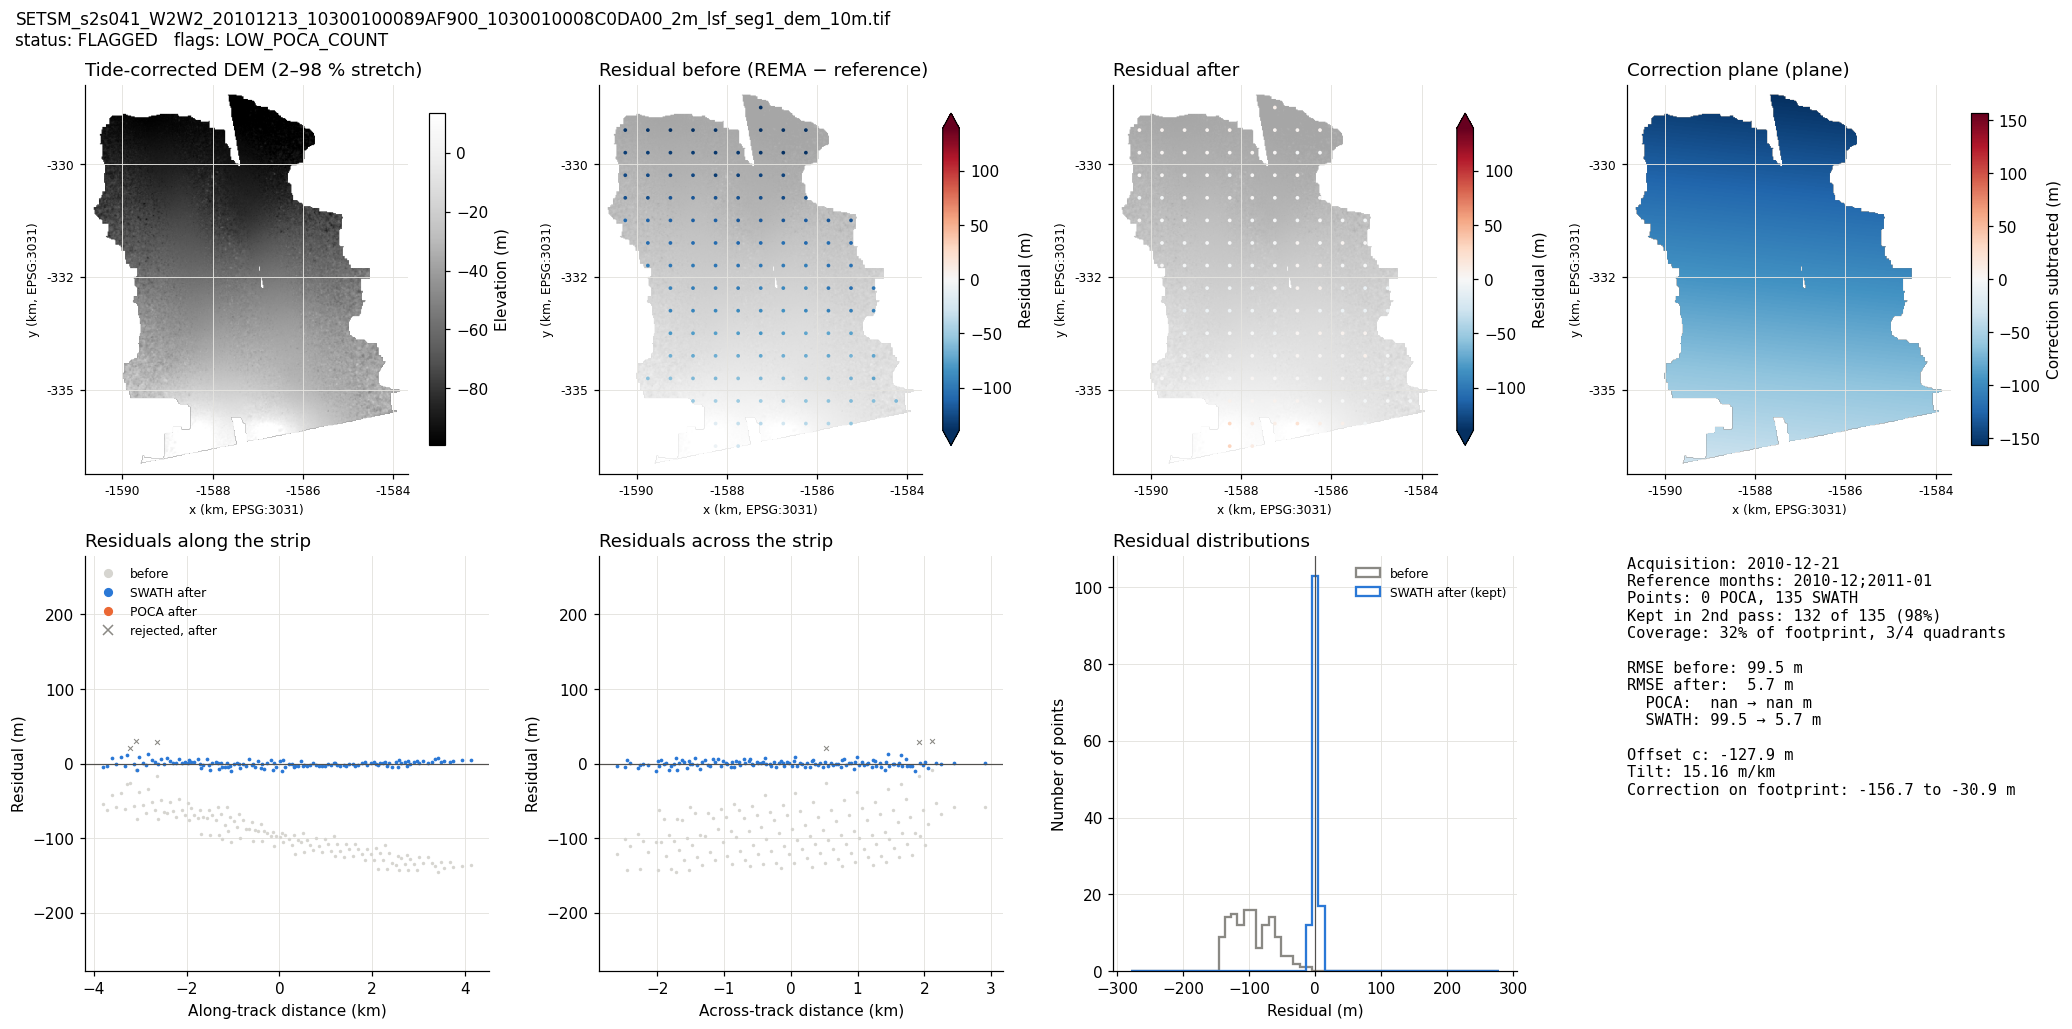

In [20]:
example_good = qc.loc[(qc["status"] != "UNCORRECTED") & (qc["n_poca"] == 0)].nlargest(1, "max_abs_correction")["strip"].iloc[0]
_ = show_strip(example_good)

A strip where the DEM itself is bad: most points are rejected in the second pass, and the plane is fitted to the few that remain.

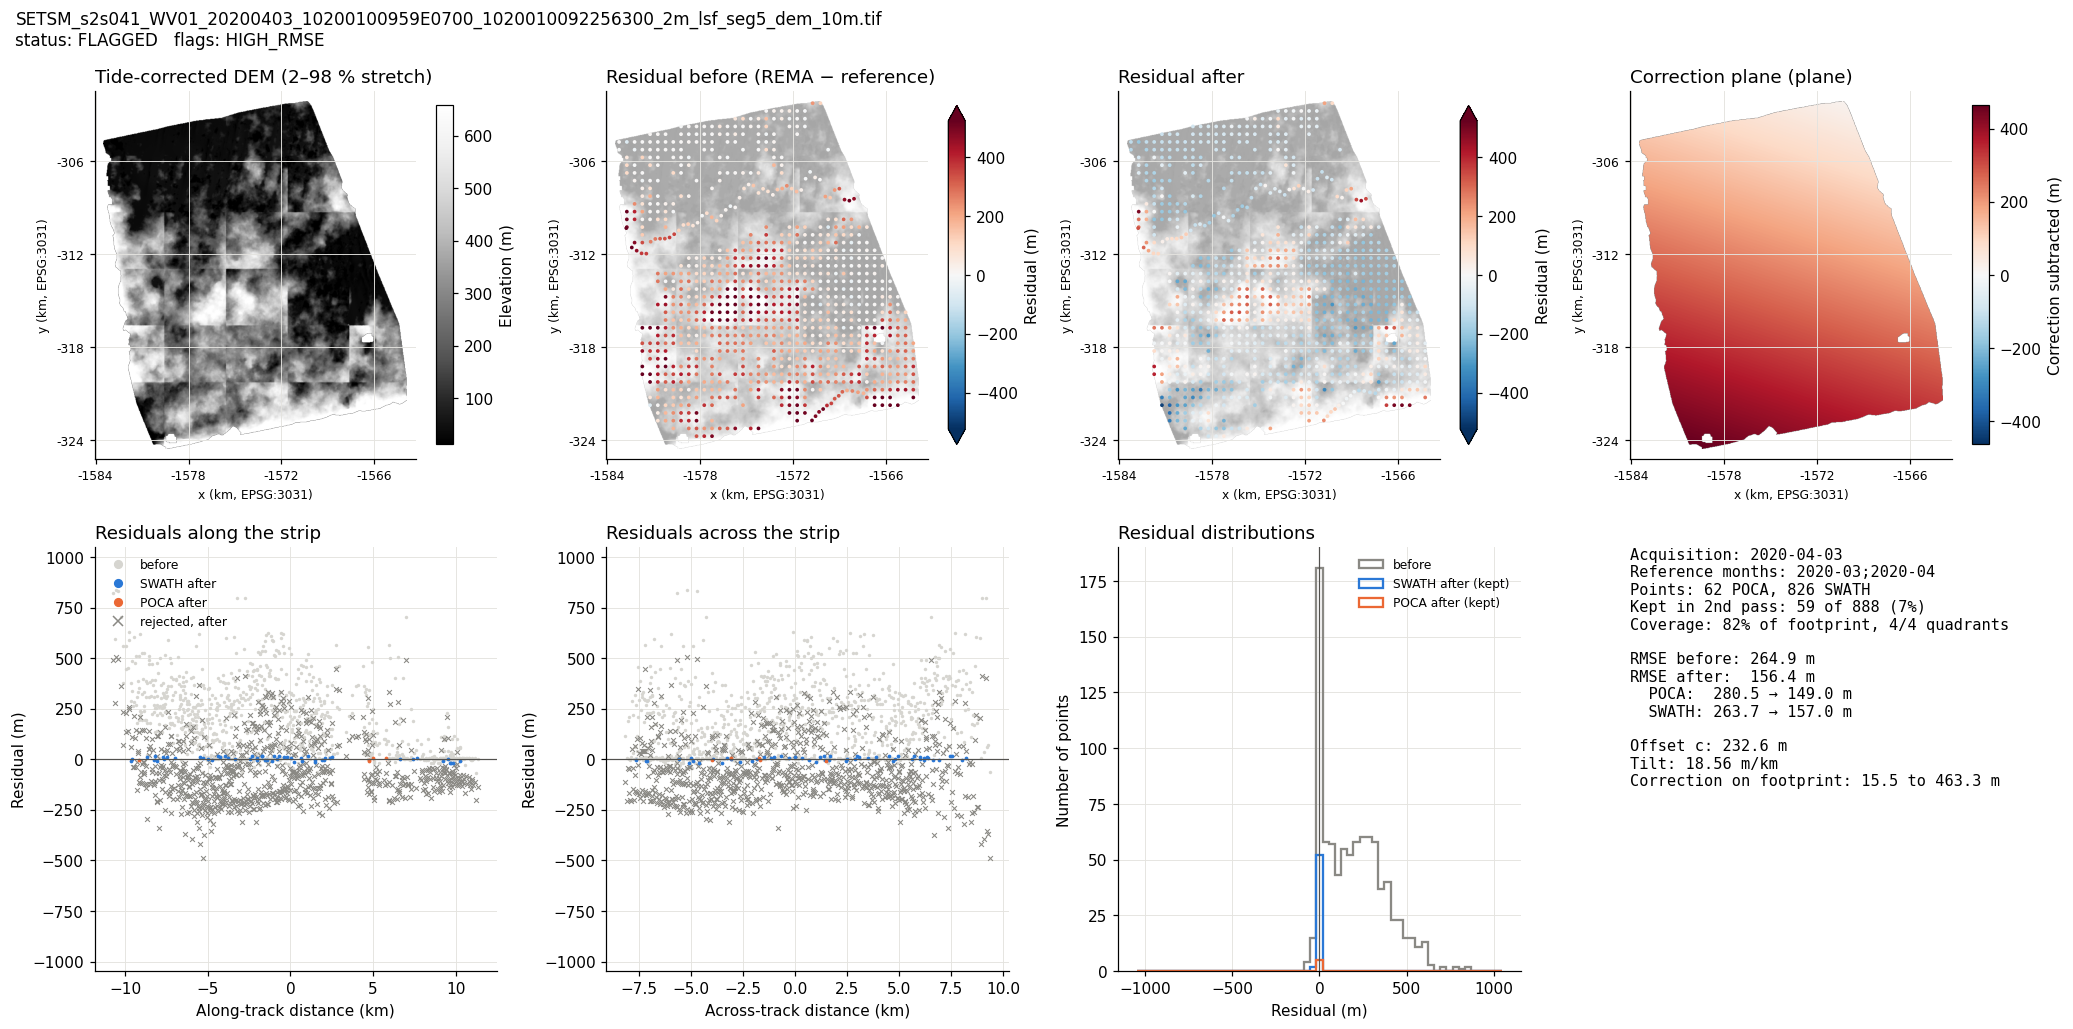

In [21]:
example_bad = qc.loc[qc["rmse_before"].idxmax(), "strip"]
_ = show_strip(example_bad)

## Points rejected in the second pass

The fraction of points rejected in the second pass separates bad DEMs from strips that are only offset. `coregistration` raises `HIGH_REJECTION` when it is above `max_rejected_fraction`.

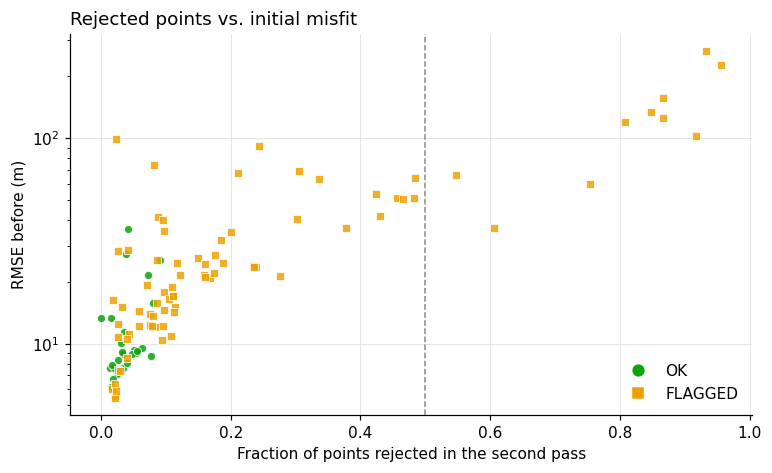

,strip,status,quality_flags,acquisition_time,n_total,rejected_fraction,rmse_before,rmse_after,c,tilt_m_per_km
55,SETSM_s2s041_WV01_20200403_10200100959E0700_10...,FLAGGED,HIGH_RMSE,2020-04-03 18:48:34+00:00,160,0.96,226.68,192.55,-19.20,48.76
61,SETSM_s2s041_WV01_20200403_10200100959E0700_10...,FLAGGED,HIGH_RMSE,2020-04-03 18:48:36+00:00,888,0.93,264.90,156.42,232.61,18.56
59,SETSM_s2s041_WV01_20200403_10200100959E0700_10...,FLAGGED,HIGH_RMSE,2020-04-03 18:48:35+00:00,505,0.92,102.19,87.00,43.77,9.29
58,SETSM_s2s041_WV01_20200403_10200100959E0700_10...,FLAGGED,HIGH_RMSE,2020-04-03 18:48:36+00:00,254,0.87,156.35,104.82,106.72,28.86
90,SETSM_s2s041_WV02_20151031_103001004CC8CF00_10...,FLAGGED,HIGH_RMSE,2015-10-31 14:08:38+00:00,1082,0.87,125.55,86.25,42.06,17.53
43,SETSM_s2s041_WV01_20151005_1020010046B3BC00_10...,FLAGGED,HIGH_RMSE,2015-10-05 17:13:05+00:00,2322,0.85,133.56,103.80,22.94,5.10
12,SETSM_s2s041_W2W2_20101124_1030010007D70D00_10...,FLAGGED,LOW_POCA_COUNT;HIGH_RMSE,2010-11-29 03:47:33+00:00,99,0.81,120.18,109.17,-4.20,32.04
64,SETSM_s2s041_WV01_20201026_102001009FAFCE00_10...,FLAGGED,HIGH_RMSE;RMSE_INCREASED,2020-10-26 18:12:25+00:00,1358,0.75,59.60,61.06,-23.21,4.42
60,SETSM_s2s041_WV01_20201026_102001009FAFCE00_10...,FLAGGED,HIGH_RMSE;RMSE_INCREASED,2020-10-26 18:12:23+00:00,175,0.61,36.71,36.75,-5.35,4.80
21,SETSM_s2s041_W2W2_20101208_1030010008064E00_10...,FLAGGED,HIGH_RMSE,2010-12-10 19:47:33+00:00,115,0.55,66.20,29.16,56.43,5.51


In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in STATUS_ORDER:
    d = fitted[fitted["status"] == s]
    if len(d):
        ax.scatter(d["rejected_fraction"], d["rmse_before"], s=28, alpha=0.85,
                   edgecolor="white", linewidth=0.6, **STATUS_STYLE[s])
ax.set(yscale="log", xlabel="Fraction of points rejected in the second pass", ylabel="RMSE before (m)")
ax.set_title("Rejected points vs. initial misfit", loc="left")
ax.axvline(thresholds["max_rejected_fraction"], color="#8a8984", linestyle="--", linewidth=1)
status_legend(ax, fitted["status"].unique(), loc="lower right")
plt.show()

cols = ["strip", "status", "quality_flags", "acquisition_time", "n_total", "rejected_fraction",
        "rmse_before", "rmse_after", "c", "tilt_m_per_km"]
qc.loc[qc["rejected_fraction"] > thresholds["max_rejected_fraction"], cols].sort_values("rejected_fraction", ascending=False).round(2)

## Shortlist from layer 1

Panels for every strip on the shortlist from section 7 are saved as PNGs (inline they would make the notebook very large). Use `show_strip` below to look at any of them here.

In [23]:
panel_dir = qc_dir / "qc_panels" / "shortlist"
panel_dir.mkdir(parents=True, exist_ok=True)
for _, row in qc[qc["strip"].isin(shortlist["strip"])].iterrows():
    fig, _ = qc_tools.plot_strip_diagnostics(row["strip"], row, region_id, projectDir, fit_params)
    fig.savefig(panel_dir / f"{row['status']}_{Path(row['strip']).stem}.png", dpi=90)
    plt.close(fig)
print(f"Saved {len(shortlist)} panels to {panel_dir}")

Saved 41 panels to /Users/b513882/Library/CloudStorage/Dropbox/REMA-strips-correction/data/interim/region-PIG/REMA/co-registered-strips/qc_panels/shortlist


## Look at any strip

Set `strip` to any file name in the QC table.

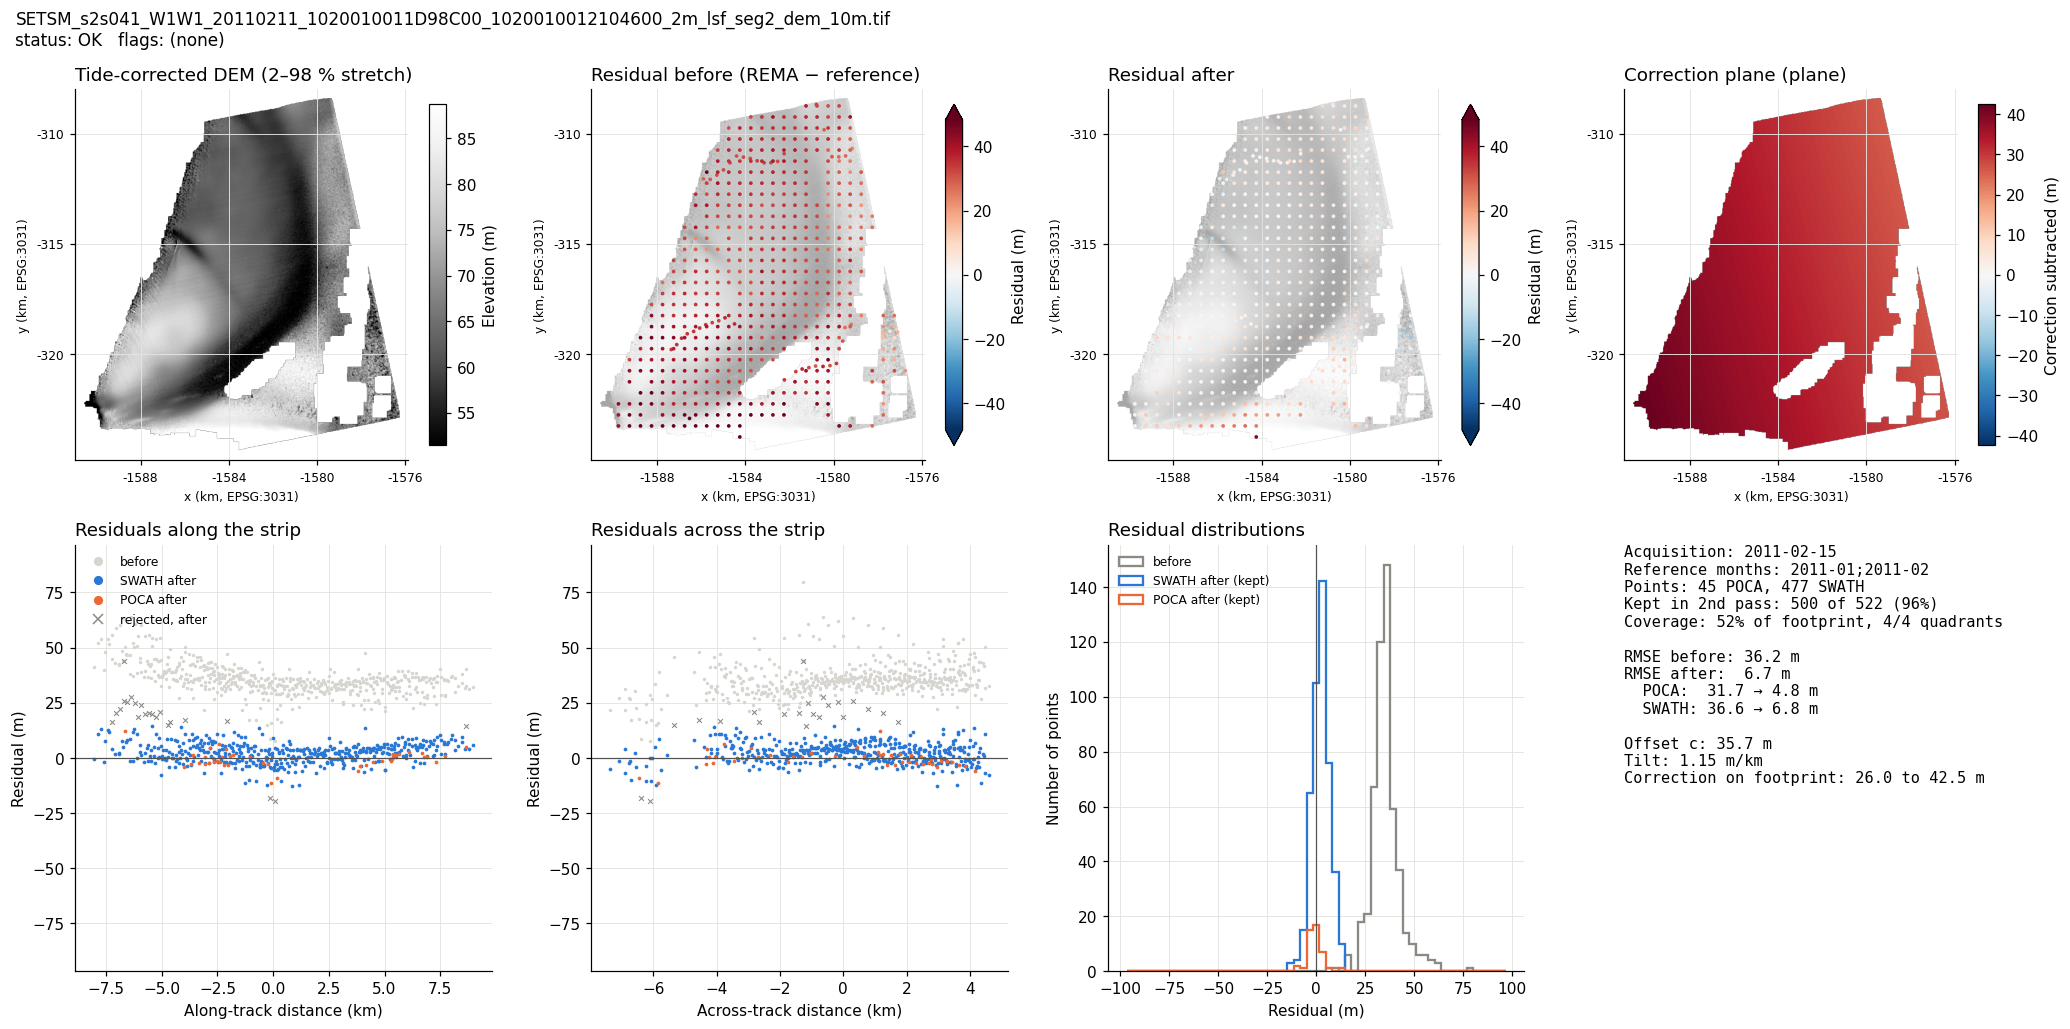

In [24]:
strip = qc.loc[qc["status"] == "OK", "strip"].iloc[0]
points = show_strip(strip)

## Save panels for all strips

Writes a PNG panel for every strip to the co-registration folder, to browse outside the notebook. This takes a few minutes.

In [25]:
save_all = False

if save_all:
    panel_dir = qc_dir / "qc_panels"
    panel_dir.mkdir(exist_ok=True)
    for _, row in qc.iterrows():
        fig, _ = qc_tools.plot_strip_diagnostics(row["strip"], row, region_id, projectDir, fit_params)
        fig.savefig(panel_dir / f"{row['status']}_{Path(row['strip']).stem}.png", dpi=90)
        plt.close(fig)
    print(f"Saved {len(qc)} panels to {panel_dir}")